# ZADATAK

Primeniti postupak klasifikacije teksta radjen na casu predavanja na zadatak analize sentimenta nad “TripAdvisor Hotel Reviews” dataset-om dostupnim na [Kaggle](https://www.kaggle.com/) platformi:
https://www.kaggle.com/datasets/thedevastator/tripadvisor-hotel-review-sentiment-analysis

Za zadatak klasifikacije, kreirati izlaznu varijablu na osnovu varijable Rating, tako da vrednosti 1 i 2 predstavljaju negativan sentiment, vrednost 3 odgovara neutralnom sentimentu, dok 4 i 5 odrazavaju pozitivan sentiment.

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV

from sklearn import metrics
from sklearn.metrics import ConfusionMatrixDisplay

from sklearn.base import TransformerMixin, BaseEstimator

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

import spacy

from pathlib import Path

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [2]:
RAND_STATE = 1

#### UCITAVANJE I PREGLED PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'trip_advisor_hotel_reviews.csv', encoding='latin')

display(data.head())

print(data.info())

,S.No.,Review,Rating
0,1,nice hotel expensive parking got good deal sta...,4
1,2,ok nothing special charge diamond member hilto...,2
2,3,nice rooms not 4* experience hotel monaco seat...,3
3,4,unique \tgreat stay \twonderful time hotel mon...,5
4,5,great stay great stay \twent seahawk game awes...,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20491 entries, 0 to 20490
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   S.No.   20491 non-null  int64 
 1   Review  20491 non-null  object
 2   Rating  20491 non-null  int64 
dtypes: int64(2), object(1)
memory usage: 480.4+ KB
None


#### KREIRANJE IZLAZNE VARIJABLE

In [4]:
def rating_to_sentiment(rating):
    if rating == 1 or rating == 2: return 'negative'
    if rating == 3: return 'neutral'
    return 'positive'


data['Sentiment'] = data.Rating.apply(rating_to_sentiment)

print(data.Sentiment.value_counts())
print(data.Sentiment.value_counts(normalize=True))
# postoji CLASS IMBALANCE -> koristicemo SMOTE

Sentiment
positive    15093
negative     3214
neutral      2184
Name: count, dtype: int64
Sentiment
positive    0.736567
negative    0.156849
neutral     0.106583
Name: proportion, dtype: float64


#### PREDIKTORI

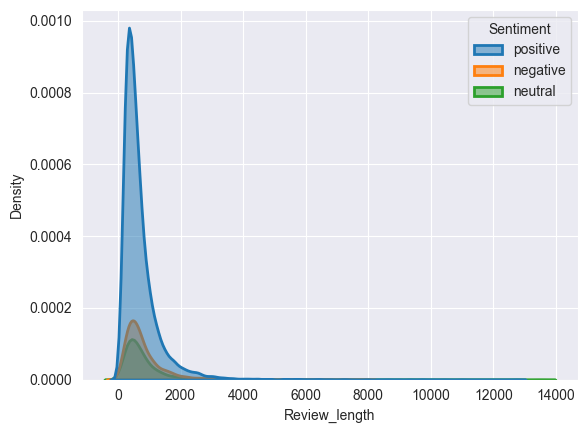

In [5]:
import seaborn as sb
import matplotlib.pyplot as plt

# provera da li duzina rezencije ima uticaja
data['Review_length'] = data.Review.apply(len)

plt.figure()
sb.kdeplot(data=data, x='Review_length', hue='Sentiment', fill=True, common_norm=True, alpha=0.5, linewidth=2)
plt.show()

# vrednosti izlazne varijable imaju slicnu raspodelu duzine rezencije -> necemo koristiti kao prediktor
# kao prediktor ostaje samo review

#### PODELA NA TRAIN I TEST

In [6]:
X = data.Review
y = data.Sentiment

y_encodings, y_levels = pd.factorize(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encodings, test_size=0.2, random_state=RAND_STATE,
                                                    stratify=y_encodings)

#### KREIRANJE CUSTOM KLASE TRANSFORMATORA

In [7]:
class ReviewVectorizer(BaseEstimator, TransformerMixin):

    def __init__(self, spacy_pipeline, vector_dimension=300):
        self.spacy_pipeline = spacy_pipeline
        self.vector_dimension = vector_dimension

    def spacy_tokenizer(self, doc):
        # pretvaranje dokumenta (rezencije) u tokene
        tokens = self.spacy_pipeline(doc)
        tokens = [token for token in tokens
                  if ((not token.is_punct) and (not token.like_num)
                      and (not token.like_url) and (not token.is_space)
                      and (not token.is_stop))]
        words = [token.lemma_.lower() for token in tokens]
        return words

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # za svaku rezenciju pravimo visedimenzionalni vektor, koji se dobija kao prosek vektora svih reci dokumenta po dimenziji
        # X - svi dokumenti
        X_transformed = np.zeros((len(X), self.vector_dimension))
        for i, text in enumerate(X):
            words = self.spacy_tokenizer(text)
            X_transformed[i] = self.spacy_pipeline(' '.join(words)).vector
        return X_transformed

In [8]:
spacy_pipeline = spacy.load('en_core_web_md', disable=['parser', 'ner'])

#### KREIRANJE I TRENING PIPELINE-ova

Napravicemo dva pipeline-a, koji koriste isti **transformator** (`ReviewVectorizer`) za prediktor, ali dva razlicita klasifikatora (`LR` i `SVM`). Pre klasifikacije uradicemo i `SMOTE` zbog **class imbalance**.

In [9]:
# vektorizacija podataka - POTREBNO VREME zbog velikog broja podataka (oko 5 minuta) !!!
# radimo ovde jer oba pipeline moraju odraditi, a ovako stedimo vreme

vectorizer = ReviewVectorizer(spacy_pipeline=spacy_pipeline)

X_train_vectors = vectorizer.fit_transform(X_train)
X_test_vectors = vectorizer.fit_transform(X_test)

In [10]:
smote = SMOTE(random_state=RAND_STATE)

# LR
lr_classifier = LogisticRegression(random_state=RAND_STATE, max_iter=2000)

lr_pipe = Pipeline(
    steps=[
        ('smote', smote),
        ('classifier', lr_classifier)
    ],
    verbose=True
)

lr_pipe.fit(X_train_vectors, y_train)

[Pipeline] ............. (step 1 of 2) Processing smote, total=   2.8s
[Pipeline] ........ (step 2 of 2) Processing classifier, total=   7.5s


,steps,"[('smote', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,True
,sampling_strategy,'auto'
,random_state,1
,k_neighbors,5
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False


In [11]:
# SVM
svm_classifier = SVC(C=1, kernel='linear', random_state=RAND_STATE, decision_function_shape='ovo')

svm_pipe = Pipeline(
    steps=[
        ('smote', smote),
        ('classifier', svm_classifier)
    ],
    verbose=True
)

svm_pipe.fit(X_train_vectors, y_train)

[Pipeline] ............. (step 1 of 2) Processing smote, total=   0.4s
[Pipeline] ........ (step 2 of 2) Processing classifier, total= 4.3min


,steps,"[('smote', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,True
,sampling_strategy,'auto'
,random_state,1
,k_neighbors,5
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'


#### EVALUACIJA

LR:


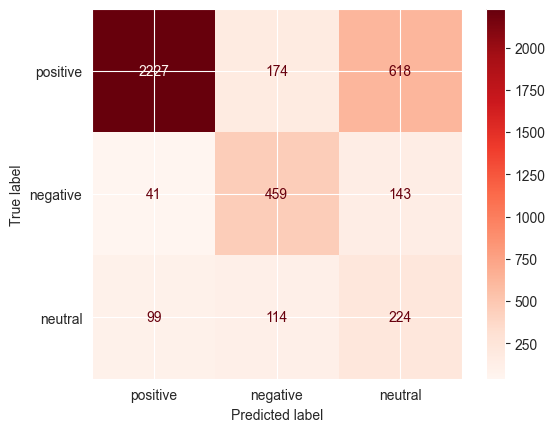

SVM:


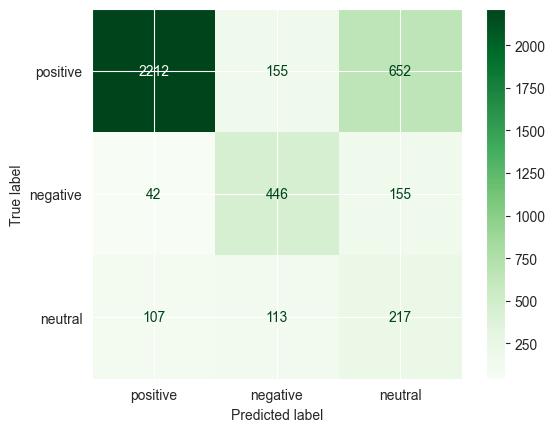

In [12]:
print('LR:')
ConfusionMatrixDisplay.from_estimator(
    lr_pipe,
    X_test_vectors,
    y_test,
    display_labels=y_levels,
    cmap='Reds'
)
plt.show()

print('SVM:')
ConfusionMatrixDisplay.from_estimator(
    svm_pipe,
    X_test_vectors,
    y_test,
    display_labels=y_levels,
    cmap='Greens'
)
plt.show()

In [13]:
lr_predictions = lr_pipe.predict(X_test_vectors)

svm_predictions = svm_pipe.predict(X_test_vectors)

#### UPOREDJIVANJE DOBIJENIH MODELA

In [14]:
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy='stratified')

dummy_clf.fit(X_train, y_train)

dummy_pred = dummy_clf.predict(X_test)

In [15]:
def get_model_metrics(y_true, y_pred, model_name):
    report = metrics.classification_report(y_true, y_pred, output_dict=True)

    b_acc = metrics.balanced_accuracy_score(y_true, y_pred)

    macro_avg = report['macro avg']
    weighted_avg = report['weighted avg']

    results = {
        'Model': model_name,
        'Macro Precision': macro_avg['precision'],
        'Macro Recall': macro_avg['recall'],
        'Macro F1-Score': macro_avg['f1-score'],
        'Weighted Precision': weighted_avg['precision'],
        'Weighted Recall': weighted_avg['recall'],
        'Weighted F1-Score': weighted_avg['f1-score'],
        'Balanced Accuracy': b_acc
    }

    return results

In [16]:
model_predictions = {
    'W2V_LR': lr_predictions,
    'W2V_LinSVM': svm_predictions,
    'DUMMY': dummy_pred
}

all_results = list()

for model_name, model_pred in model_predictions.items():
    model_res = get_model_metrics(y_test, model_pred, model_name)
    all_results.append(model_res)

all_results_df = pd.DataFrame(all_results)
all_results_df.set_index("Model", inplace=True)
all_results_df = all_results_df.apply(lambda x: round(x, 4))

print(all_results_df)

            Macro Precision  Macro Recall  Macro F1-Score  Weighted Precision  \
Model                                                                           
W2V_LR               0.5942        0.6547          0.6008              0.8136   
W2V_LinSVM           0.5912        0.6410          0.5922              0.8106   
DUMMY                0.3441        0.3441          0.3441              0.5848   

            Weighted Recall  Weighted F1-Score  Balanced Accuracy  
Model                                                              
W2V_LR               0.7099             0.7463             0.6547  
W2V_LinSVM           0.7014             0.7404             0.6410  
DUMMY                0.5845             0.5847             0.3441  


#### PODESAVANJE HIPERPARAMETARA

*trajace predugo...*